# 02. Markov chains and HMMs for customer lifecycle

## Business use

Lifecycle stages drive retention spend, customer lifetime value, and when to recommend. Downstream services need, per customer: state probabilities, the most likely state, a next-period forecast, the probability of purchase next week, and expected time to churn.

## Intuition

A Markov chain says where a customer goes next depends only on where they are now. In a hidden Markov model we never see the state, only what they do. One quiet week does not flip a loyal customer to churned, because the state (engaged, cooling, dormant) is separated from the noisy signal (no visit, browse, purchase).

## Math

$$
P_{ij} = P(s_{t+1} = j \mid s_t = i), \quad \pi = \pi P, \quad \sum_i \pi_i = 1
$$

If churn is absorbing, let $Q$ be the transitions among the transient states. Expected time to absorption is

$$
N = (I - Q)^{-1}, \quad t = N \mathbf{1}.
$$

An HMM with transition matrix $A$ and emission matrix $B$ has

$$
p(x, z) = \pi_{z_1} \prod_{t=2}^{T} A_{z_{t-1} z_t} \prod_{t=1}^{T} B_{z_t x_t}.
$$

Three jobs: evaluation (forward algorithm, $p(x)$), decoding (Viterbi for the single best path; forward-backward for $P(z_t \mid \text{all } x)$), and learning (Baum-Welch, which is EM, fits $\pi$, $A$ and $B$).

Use a Markov chain when the state is a business rule you already observe (new, active, at-risk, churned by recency). Use an HMM when engagement is latent and you only see behaviour.


## Step 1. Observed chain: count transitions

Three thousand customers, twelve monthly states, churn absorbing. The MLE transition matrix is the row-normalised counts.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from hmmlearn import hmm
from IPython.display import display

rng = np.random.default_rng(3)
states = ["New", "Active", "At-risk", "Churned"]
p_true = np.array(
    [
        [0.00, 0.60, 0.30, 0.10],
        [0.00, 0.80, 0.15, 0.05],
        [0.00, 0.35, 0.40, 0.25],
        [0.00, 0.00, 0.00, 1.00],
    ]
)
sequences = []
for _ in range(3000):
    state = [0]
    for _ in range(11):
        state.append(int(rng.choice(4, p=p_true[state[-1]])))
    sequences.append(state)

counts = np.zeros((4, 4))
for sequence in sequences:
    for left, right in zip(sequence[:-1], sequence[1:], strict=True):
        counts[left, right] += 1
p_hat = counts / counts.sum(1, keepdims=True)
np.set_printoptions(precision=3, suppress=True)
print("customers:", len(sequences), "months per customer:", len(sequences[0]))
print("MLE transition matrix (rows=from, cols=to):")
print(p_hat)

customers: 3000 months per customer: 12
MLE transition matrix (rows=from, cols=to):
[[0.    0.607 0.298 0.094]
 [0.    0.8   0.149 0.051]
 [0.    0.34  0.408 0.253]
 [0.    0.    0.    1.   ]]


## Step 2. Uncertainty on one row

Each row is a probability vector. With a Dirichlet(1) prior the posterior is Dirichlet(1 + counts). Below, the Active to Churned probability.


In [2]:
active_to = rng.dirichlet(1 + counts[1], size=4000)
lo, hi = np.quantile(active_to[:, 3], [0.03, 0.97])
print(f"Active->Churned posterior mean {active_to[:, 3].mean():.3f}, 94% interval ({lo:.3f}, {hi:.3f})")

Active->Churned posterior mean 0.051, 94% interval (0.047, 0.054)


## Step 3. Absorbing chain, then a chain that can reactivate

With Churned absorbing, $N = (I - Q)^{-1}$ gives expected months to churn. $P^6$ is the state mix six months after acquisition.

If customers can come back, there is no absorbing state. The stationary distribution is the left eigenvector of $P$ for eigenvalue 1. Check $\pi P = \pi$.


In [3]:
transient = p_hat[:3, :3]
fundamental = np.linalg.inv(np.eye(3) - transient)
print("expected months to churn from New/Active/At-risk:", fundamental.sum(1))
print("state distribution in 6 months for a new customer:", np.linalg.matrix_power(p_hat, 6)[0])

p_ergodic = np.array(
    [
        [0.80, 0.15, 0.05],
        [0.35, 0.40, 0.25],
        [0.10, 0.10, 0.80],
    ]
)
eigenvalues, eigenvectors = np.linalg.eig(p_ergodic.T)
stationary = np.real(eigenvectors[:, np.argmin(np.abs(eigenvalues - 1))])
stationary = stationary / stationary.sum()
print("stationary distribution (Active, At-risk, Dormant):", stationary)
print("check pi @ P:", stationary @ p_ergodic)

expected months to churn from New/Active/At-risk: [10.025 10.946  7.967]
state distribution in 6 months for a new customer: [0.    0.403 0.122 0.476]
stationary distribution (Active, At-risk, Dormant): [0.481 0.177 0.342]
check pi @ P: [0.481 0.177 0.342]


## Step 4. Hidden engagement

Five hundred customers, 26 weeks. Hidden states are Engaged, Cooling, Dormant. Each week we see one symbol: 0 no visit, 1 browse, 2 purchase. `lengths` stops one customer's sequence from running into the next.

Baum-Welch is EM, so it finds local optima. Fit several restarts and keep the best log-likelihood. State numbers are arbitrary: sort by $P(\text{no visit})$ and name the least-absent state Engaged.


In [4]:
transition_true = np.array(
    [
        [0.85, 0.12, 0.03],
        [0.20, 0.60, 0.20],
        [0.03, 0.07, 0.90],
    ]
)
emission_true = np.array(
    [
        [0.10, 0.50, 0.40],
        [0.45, 0.45, 0.10],
        [0.90, 0.09, 0.01],
    ]
)
start_true = np.array([0.6, 0.3, 0.1])
symbols = []
hidden = []
lengths = []
for _ in range(500):
    weeks = 26
    state = [int(rng.choice(3, p=start_true))]
    for _ in range(weeks - 1):
        state.append(int(rng.choice(3, p=transition_true[state[-1]])))
    symbols.extend(int(rng.choice(3, p=emission_true[k])) for k in state)
    hidden.extend(state)
    lengths.append(weeks)
observations = np.array(symbols).reshape(-1, 1)
hidden = np.array(hidden)
print("customer-weeks:", int(observations.size), "customers:", len(lengths))

best = None
for seed in range(5):
    candidate = hmm.CategoricalHMM(n_components=3, n_iter=200, tol=1e-4, random_state=seed)
    candidate.fit(observations, lengths)
    score = candidate.score(observations, lengths)
    if best is None or score > best[0]:
        best = (score, candidate)
score, fitted = best
# Least P(no visit) is the most engaged state.
order = np.argsort(fitted.emissionprob_[:, 0])
history = np.asarray(fitted.monitor_.history)
print("HMM log-likelihood:", round(score, 1))
print("converged flag:", fitted.monitor_.converged, "iters:", fitted.monitor_.iter)
print("last loglik gain:", round(float(history[-1] - history[-2]), 4))
print("learned transmat (Engaged, Cooling, Dormant):")
print(fitted.transmat_[np.ix_(order, order)])
print("true transmat:")
print(transition_true)
print("learned emissionprob (no visit, browse, purchase):")
print(fitted.emissionprob_[order])
print("true emissionprob:")
print(emission_true)
print("startprob:", fitted.startprob_[order])

customer-weeks: 13000 customers: 500


HMM log-likelihood: -11741.1
converged flag: True iters: 200
last loglik gain: 0.1446
learned transmat (Engaged, Cooling, Dormant):
[[0.916 0.084 0.   ]
 [0.061 0.495 0.444]
 [0.073 0.218 0.709]]
true transmat:
[[0.85 0.12 0.03]
 [0.2  0.6  0.2 ]
 [0.03 0.07 0.9 ]]
learned emissionprob (no visit, browse, purchase):
[[0.143 0.505 0.352]
 [0.674 0.319 0.007]
 [0.949 0.029 0.022]]
true emissionprob:
[[0.1  0.5  0.4 ]
 [0.45 0.45 0.1 ]
 [0.9  0.09 0.01]]
startprob: [0.742 0.24  0.017]


## Step 5. How many hidden states?

Fit $k = 2, 3, 4$ from three random starts and compare BIC and AIC. Lower is better. BIC penalises extra parameters more than AIC (about $\ln n$ per parameter versus 2). They can disagree when two states have similar emissions: the criterion is evidence, not a verdict. Check that a state is big enough to act on and stable across refits.


In [5]:
print("k  logL  BIC  AIC")
for n_states in (2, 3, 4):
    chosen = None
    for seed in range(3):
        candidate = hmm.CategoricalHMM(n_components=n_states, n_iter=200, random_state=seed)
        candidate.fit(observations, lengths)
        candidate_score = candidate.score(observations, lengths)
        if chosen is None or candidate_score > chosen[0]:
            chosen = (candidate_score, candidate)
    chosen_score, chosen_model = chosen
    print(
        f"k={n_states}  logL={chosen_score:.1f}  "
        f"BIC={chosen_model.bic(observations, lengths):.1f}  "
        f"AIC={chosen_model.aic(observations, lengths):.1f}"
    )

k  logL  BIC  AIC


k=2  logL=-11756.6  BIC=23579.6  AIC=23527.3


k=3  logL=-11741.1  BIC=23614.8  AIC=23510.2


k=4  logL=-11733.3  BIC=23684.6  AIC=23512.7


## Step 6. Decode one customer and forecast next week

Viterbi is the single most likely path. Forward-backward is $P(\text{state})$ each week, which is what a service should store. Next week is the last posterior times $A$. Purchase probability is that forecast times $P(\text{purchase} \mid \text{state})$.

In hmmlearn 0.3, `monitor_.converged` is also true when the fit simply hits `n_iter`. Check `monitor_.iter` and the last gain in the history. If the gain is still large at iteration 200, the flag is not evidence of convergence.


In [6]:
inverse = np.argsort(order)
customer = observations[:26]
_, viterbi = fitted.decode(customer, algorithm="viterbi")
posterior = fitted.predict_proba(customer)[:, order]
names = np.array(["Engaged", "Cooling", "Dormant"])
observed_name = np.array(["none", "browse", "buy"])
print("customer 0 observations :", " ".join(observed_name[customer.ravel()]))
print("Viterbi path            :", " ".join(names[inverse[viterbi]]))
print("true hidden path        :", " ".join(names[hidden[:26]]))
print("last 4 weeks P(state) [Engaged, Cooling, Dormant]:")
print(np.round(posterior[-4:], 3))
forecast = posterior[-1] @ fitted.transmat_[np.ix_(order, order)]
purchase = float(forecast @ fitted.emissionprob_[order][:, 2])
print("next-week state forecast:", np.round(forecast, 3), " P(purchase next week)=", round(purchase, 3))
predicted = inverse[fitted.predict(observations, lengths)]
accuracy = float(np.mean(predicted == hidden))
print("Viterbi accuracy vs truth (all customers):", round(accuracy, 3))

customer 0 observations : browse browse buy none browse buy browse browse buy browse browse browse browse browse browse browse browse browse browse browse browse buy browse browse buy browse
Viterbi path            : Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged Engaged
true hidden path        : Engaged Engaged Engaged Cooling Engaged Engaged Engaged Engaged Engaged Engaged Cooling Cooling Engaged Engaged Engaged Engaged Engaged Engaged Cooling Cooling Engaged Engaged Engaged Engaged Engaged Engaged
last 4 weeks P(state) [Engaged, Cooling, Dormant]:
[[0.994 0.006 0.   ]
 [0.994 0.006 0.   ]
 [0.998 0.001 0.001]
 [0.944 0.056 0.   ]]
next-week state forecast: [0.868 0.107 0.025]  P(purchase next week)= 0.307
Viterbi accuracy vs truth (all customers): 0.745


## Step 7. Forward algorithm by hand

Scaled forward recursion. The sum of the log scales is $\log p(x)$ and should match `hmmlearn` on one sequence. Use the model's own state order, not the relabelled one.


hand-coded forward: -23.1257 hmmlearn score: -23.1257


/tmp/ipykernel_55275/120038507.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


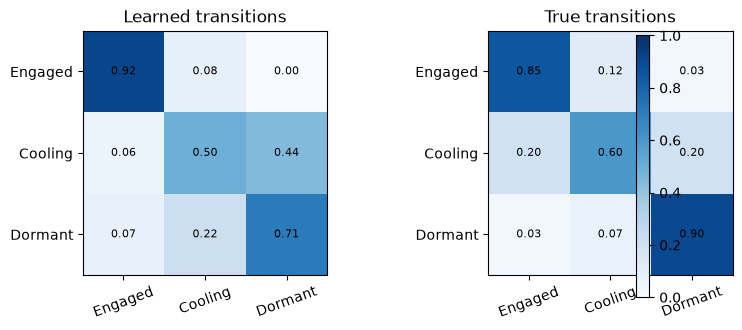

In [7]:
def forward_loglik(
    sequence: np.ndarray, start: np.ndarray, transition: np.ndarray, emission: np.ndarray
) -> float:
    alpha = start * emission[:, sequence[0]]
    scale = alpha.sum()
    alpha = alpha / scale
    loglik = np.log(scale)
    for symbol in sequence[1:]:
        alpha = (alpha @ transition) * emission[:, symbol]
        scale = alpha.sum()
        alpha = alpha / scale
        loglik = loglik + np.log(scale)
    return float(loglik)


hand = forward_loglik(customer.ravel(), fitted.startprob_, fitted.transmat_, fitted.emissionprob_)
library = float(fitted.score(customer))
print("hand-coded forward:", round(hand, 4), "hmmlearn score:", round(library, 4))
assert abs(hand - library) < 1e-3

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.4))
learned = fitted.transmat_[np.ix_(order, order)]
for ax, matrix, title in (
    (axes[0], learned, "Learned transitions"),
    (axes[1], transition_true, "True transitions"),
):
    image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks([0, 1, 2], names, rotation=20)
    ax.set_yticks([0, 1, 2], names)
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes, fraction=0.046)
fig.tight_layout()
display(fig)
plt.close(fig)

## How to read the outputs

| Output | How to read it |
|---|---|
| Transition matrix | Rows sum to 1. The diagonal is persistence. Expected stay is $1/(1-P_{ii})$: Active at 0.80 lasts about 5 months; Engaged at 0.92 lasts about 12 weeks. |
| Absorbing chain | A new customer lasts on the order of 10 months before churn. At 6 months, roughly half of a new cohort may already be churned. |
| Stationary distribution | Long-run share in each state if nothing changes. $\pi P$ must return $\pi$. |
| `emissionprob_` | What a hidden state looks like. Engaged buys often; Dormant is mostly "no visit". This is how you name states. |
| Viterbi path | One path. A single quiet week often stays Engaged: the hard path is sticky. |
| Forward-backward | $P(\text{state})$ per week. This is what downstream services should consume. |
| BIC vs AIC | They can pick different $k$ when two states look alike. Truth being 3 does not mean BIC must say 3. |
| Score and accuracy | In production there is no hidden truth. Validate on held-out sequences. |

A reference run on this simulation had Active to Churned near 0.051 (94% interval about 0.047 to 0.054), expected time to churn from Active near 11 months, HMM log-likelihood near -11741, and Viterbi accuracy near 0.75. Local optima move the third digit; the reading does not change.

## Pitfalls

- Label switching: state 0 in one fit is state 2 in the next. Relabel by emissions before publishing ids.
- Baum-Welch stops in local optima. Always restart.
- `monitor_.converged` is true at the iteration cap in hmmlearn 0.3. Read `iter` and the history.
- A constant transition matrix ignores holiday peaks. Add covariates or fit by season.
- Shipping the hard Viterbi path when the consumer needed probabilities.
- Defining "churned" with future information leaks the label into the features.


## How to explain this to a CTO


In [8]:
print(
    f"Every customer gets a weekly probability of being engaged, cooling, or dormant. "
    f"This customer has a {forecast[0]:.0%} chance of still being engaged next week "
    f"and a {purchase:.0%} chance of buying, so we do not spend retention budget on them. "
    "We trigger an offer only when the probability of being dormant crosses a threshold "
    "tuned against the cost of the campaign."
)
print(
    "The online update is one matrix-vector product when the week closes. "
    "Parameters are refit offline and versioned. The service stores probabilities, not a hard label."
)

Every customer gets a weekly probability of being engaged, cooling, or dormant. This customer has a 87% chance of still being engaged next week and a 31% chance of buying, so we do not spend retention budget on them. We trigger an offer only when the probability of being dormant crosses a threshold tuned against the cost of the campaign.
The online update is one matrix-vector product when the week closes. Parameters are refit offline and versioned. The service stores probabilities, not a hard label.


## Check yourself

**Markov chain or HMM?**
If the state is a rule you already code (recency buckets), estimate the transition matrix, put a Dirichlet prior on each row, and use the fundamental matrix for time to churn. If engagement is latent, fit an HMM: Baum-Welch for parameters, forward-backward for weekly probabilities, Viterbi only when a single path is actually required.

**What should an event-driven consumer keep?**
The current state-probability vector. On the next session or the week close, update it and publish an event when the top state or the churn probability crosses a threshold.
